# Spotify EDA: Artist Master

**Purpose:** Explain what is in this Spotify dataset, check its quality, and highlight a few useful patterns.

**Audience:** Technical and non-technical readers. Charts and summaries describe the source data. They do not clean or change it.

**Run order:** Run cells from top to bottom. The CSV should be under `data/raw/` in your project.

---

## 1. Load the dataset

Find the latest local CSV automatically from the project directory. No database connection is needed.

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

filename = 'artists.csv'
working_dir = Path.cwd().resolve()
folders = [p / "data" / "raw" for p in (working_dir, *working_dir.parents)]
folders.append(working_dir)
files = [folder / filename for folder in folders if (folder / filename).is_file()]
if not files:
    raise FileNotFoundError(f"Could not find {filename} in data/raw/.")

source = files[0]
df = pd.read_csv(source, low_memory=False)
print("Source:", source)
print(f"Rows: {len(df):,} | Columns: {len(df.columns)}")

Source: C:\Users\enric\OneDrive\Documents\Programming Folders\Python and JupyterNB Scripts\Spotify Analytics\data\raw\artists.csv
Rows: 74,292 | Columns: 6


---

## 2. Dataset overview

Look at a few records and the available columns. A row represents one source record, not necessarily one unique artist, song, or album.

In [15]:
display(df.head(5))
print("Columns:", ", ".join(df.columns))


,artist_uri,artist_name,monthly_listeners,monthly_listeners_rank,monthly_listeners_peak_rank,monthly_listeners_peak_listeners
0,spotify:artist:5csAaiFcC1qKkVPgUJfXID,Zulu Queens,NaN,NaN,NaN,NaN
1,spotify:artist:2h9NlcdGxIEnnh5aQuSeZ1,Lwah Ndlunkulu,1160779.0,12794.0,NaN,1236495.0
2,spotify:artist:5kwZB1xNLgB3lln1JGS2B9,MaWhoo,2746109.0,5837.0,NaN,2868014.0
3,spotify:artist:1UwTwoC4T1i6vzwsQgIWB0,Feza,1671939.0,9333.0,NaN,1885686.0
4,spotify:artist:6Wqpl1YTjgy5TiTluzFzjx,Tman Xpress,1708853.0,9146.0,NaN,1811260.0


Columns: artist_uri, artist_name, monthly_listeners, monthly_listeners_rank, monthly_listeners_peak_rank, monthly_listeners_peak_listeners


---

## 3. Data quality

Missing values show information absent from the source. Duplicate keys flag records needing review. EDA does not remove records.

In [16]:
# Show only columns containing missing values.
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
if missing.empty:
    print("No missing values found.")
else:
    display(pd.DataFrame({"Missing rows": missing, "Missing %": (missing / len(df) * 100).round(1)}).head(15))

key = ['uri']
if all(column in df.columns for column in key):
    repeated = df.duplicated(subset=key).sum()
    print(f"Repeated business keys: {repeated:,}")
else:
    print("Business-key check skipped: one or more key columns are absent.")

,Missing rows,Missing %
monthly_listeners_peak_rank,71792,96.6
monthly_listeners_rank,49277,66.3
monthly_listeners,49277,66.3
monthly_listeners_peak_listeners,49277,66.3
artist_name,3,0.0


Business-key check skipped: one or more key columns are absent.


---

## 4. Key figures

These counts provide a quick picture of dataset coverage. Chart entries are observations, not unique listeners or tracks.

In [17]:
print(f"Artist records: {len(df):,}")
if "uri" in df:
    print(f"Unique artist URIs: {df['uri'].nunique():,}")
for column in ["monthly_listeners", "monthly_listeners_peak_listeners"]:
    if column in df:
        values = pd.to_numeric(df[column], errors="coerce")
        print(f"{column.replace('_', ' ').title()} | available: {values.notna().sum():,} | median: {values.median():,.0f}" if values.notna().any() else f"{column}: no numeric values")

Artist records: 74,292
Monthly Listeners | available: 25,015 | median: 1,192,344
Monthly Listeners Peak Listeners | available: 25,015 | median: 1,833,409


---

## 5. Two charts

Read the title and axes first. The charts summarize record distribution, not cause and effect.

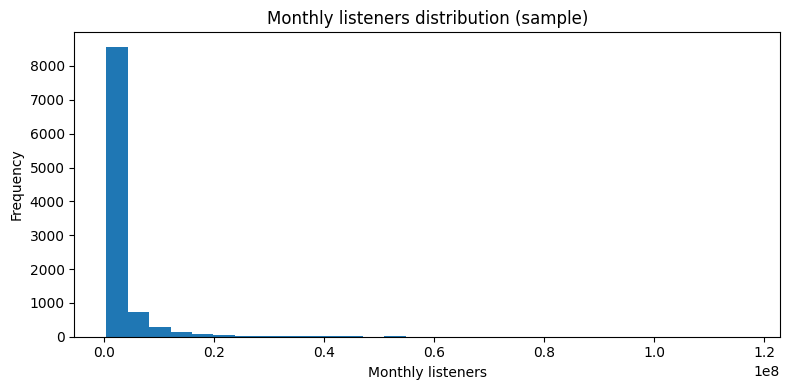

In [18]:
column = "monthly_listeners"
if column in df:
    values = pd.to_numeric(df[column], errors="coerce").dropna()
    if not values.empty:
        values = values.sample(n=min(10000, len(values)), random_state=42)
        ax = values.plot.hist(bins=30, figsize=(8, 4), title="Monthly listeners distribution (sample)")
        ax.set_xlabel("Monthly listeners")
        plt.tight_layout()
        plt.show()
    else:
        print("No monthly listener values to chart.")
else:
    print("Monthly listener column unavailable.")

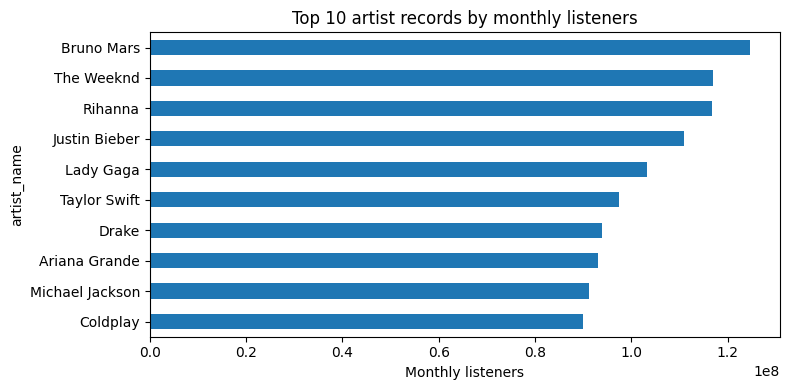

In [19]:
if {"artist_name", "monthly_listeners"}.issubset(df.columns):
    view = df[["artist_name", "monthly_listeners"]].copy()
    view["monthly_listeners"] = pd.to_numeric(view["monthly_listeners"], errors="coerce")
    top = view.dropna(subset=["monthly_listeners"]).nlargest(10, "monthly_listeners")
    if not top.empty:
        ax = top.set_index("artist_name")["monthly_listeners"].sort_values().plot.barh(figsize=(8, 4), title="Top 10 artist records by monthly listeners")
        ax.set_xlabel("Monthly listeners")
        plt.tight_layout()
        plt.show()
else:
    print("Top artist chart unavailable: required columns missing.")

---

## 6. What the findings mean

Use the outputs above to complete this short interpretation after each refresh.

- **Coverage:** How many records and unique entities appear? Which dates or markets are represented?
- **Data quality:** Which fields are missing? Are repeated business keys present?
- **Main pattern:** Which markets or statuses dominate, or how are listener counts distributed?
- **Limitation:** Repeated chart entries, unknown metrics, and source coverage affect interpretation.

**Next step:** Apply cleaning rules separately in `etl/cleaning/`. This EDA notebook does not alter or load MySQL tables.